# Rôle 1 : interprétabilité des modèles

1. Les modèles expliqués
2. SHAP : ce qui pèse dans chaque prédiction (rentabilité, puis risque)
3. Importance par permutation
4. Les 10 plus grosses erreurs
5. Fichier pour l'application : `reports/role1/shap_importance.csv`
6. Bilan

**Quels modèles ?** Les modèles choisis à la tâche 8 : Ridge pour la rentabilité, LightGBM pour le risque.

- Pour les parties 2 à 4, on explique le modèle **appris sur les 1 050 projets d'entraînement**, celui dont on a mesuré la qualité sur le test. On l'analyse sur les **450 projets de validation et de test**, qu'il n'a jamais vus.
- Pour la partie 5 (le fichier de l'application), on utilise le **modèle livré**, réappris avec les mêmes réglages sur les 1 500 projets terminés, celui qu'appelle `predict`.

Rappel : les cibles sont **simulées** par une formule connue (`data/README.md`). On peut donc vérifier si les explications retrouvent la formule, ce qui est rarement possible avec des données réelles.

In [1]:
import logging
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")  # barre de progression de shap, inutile ici
import shap
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, r2_score

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
from src import supervise

logging.basicConfig(level=logging.INFO, format="%(message)s")
warnings.filterwarnings("ignore", message="X does not have valid feature names")
GRAINE = 42
FIGURES = RACINE / "reports" / "role1" / "figures"
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Les modèles expliqués

In [2]:
jeux = supervise.charger_jeux()
entrainement = jeux["entrainement"]
bornes = supervise.bornes_rentabilite(entrainement[supervise.CIBLE_REGRESSION])
entrainement_bornes = entrainement[supervise.dans_les_bornes(entrainement, bornes)]

# Mêmes réglages qu'à la tâche 8, appris sur l'entraînement seulement.
modele_rentabilite = supervise.creer_modele_rentabilite().fit(
    entrainement_bornes[supervise.VARIABLES], entrainement_bornes[supervise.CIBLE_REGRESSION])
modele_risque = supervise.creer_modele_risque().fit(
    entrainement[supervise.VARIABLES], entrainement[supervise.CIBLE_CLASSIFICATION])

# Contrôle : on doit retrouver les chiffres du test de la tâche 8.
test = jeux["test"]
test_bornes = test[supervise.dans_les_bornes(test, bornes)]
print(f"R² test dans les bornes : {r2_score(test_bornes['rentabilite'], modele_rentabilite.predict(test_bornes[supervise.VARIABLES])):.3f}"
      " (tâche 8 : 0,469)")
print(f"Exactitude test         : {accuracy_score(test['risque'], modele_risque.predict(test[supervise.VARIABLES])):.3f}"
      " (tâche 8 : 0,671)")

evaluation = pd.concat([jeux["validation"], test], ignore_index=True)
print(len(evaluation), "projets jamais vus par ces modèles (validation + test)")

Jeux chargés : {'entrainement': 1050, 'validation': 225, 'test': 225}


R² test dans les bornes : 0.469 (tâche 8 : 0,469)
Exactitude test         : 0.671 (tâche 8 : 0,671)
450 projets jamais vus par ces modèles (validation + test)


On retrouve exactement les résultats du test : ce sont bien les modèles évalués à la tâche 8.

Le prétraitement transforme les 7 variables en 175 colonnes (une par pays, par secteur, etc.). Pour lire les explications, on **regroupe les colonnes par variable d'origine** : la contribution du « pays » d'un projet est la somme des contributions de toutes les colonnes `pays_...` (une seule vaut 1 pour un projet donné).

In [3]:
def variable_d_origine(colonne: str) -> str:
    """Variable d'origine d'une colonne encodée (pays_Morocco -> pays)."""
    for variable in supervise.VARIABLES_CATEGORIELLES:
        if colonne.startswith(variable + "_"):
            return variable
    return colonne


def regrouper(valeurs: np.ndarray, colonnes: np.ndarray) -> pd.DataFrame:
    """Somme des valeurs SHAP des colonnes d'une même variable : un projet par ligne, une variable par colonne."""
    groupes = [variable_d_origine(c) for c in colonnes]
    return pd.DataFrame(valeurs, columns=colonnes).T.groupby(groupes, sort=False).sum().T

## 2. SHAP

**Le principe.** Pour un projet, la valeur SHAP d'une variable est sa **contribution à l'écart entre la prédiction et la prédiction moyenne**. Les contributions s'additionnent : prédiction = moyenne + somme des valeurs SHAP. Elles viennent de la théorie des jeux (valeurs de Shapley) : chaque variable reçoit sa part « équitable » de l'écart.

- Pour un modèle linéaire comme Ridge, c'est simple : valeur SHAP = coefficient × (valeur du projet − valeur moyenne). On utilise `shap.LinearExplainer`.
- Pour LightGBM, `shap.TreeExplainer` calcule les valeurs exactes à partir des arbres.

L'**importance SHAP** d'une variable est la moyenne, sur les projets, de la valeur absolue de sa contribution : de combien, en moyenne, elle déplace la prédiction.

### 2.1 Rentabilité (Ridge)

In [4]:
pretraitement = modele_rentabilite["pretraitement"]
colonnes = pretraitement.get_feature_names_out()
X_fond = pretraitement.transform(entrainement_bornes[supervise.VARIABLES])
X_evaluation = pretraitement.transform(evaluation[supervise.VARIABLES])

explicateur = shap.LinearExplainer(modele_rentabilite["modele"],
                                   shap.maskers.Independent(X_fond, max_samples=len(X_fond)))
shap_rentabilite = explicateur(X_evaluation)
shap_rentabilite_variables = regrouper(shap_rentabilite.values, colonnes)

importance_rentabilite = shap_rentabilite_variables.abs().mean().sort_values(ascending=False)
importance_rentabilite.round(3).to_frame("importance SHAP (points de rentabilité)")

,importance SHAP (points de rentabilité)
secteur,1.302
duree_mois,1.137
pays,0.824
type_financement,0.587
cout_total,0.532
region,0.357
annee_approbation,0.096


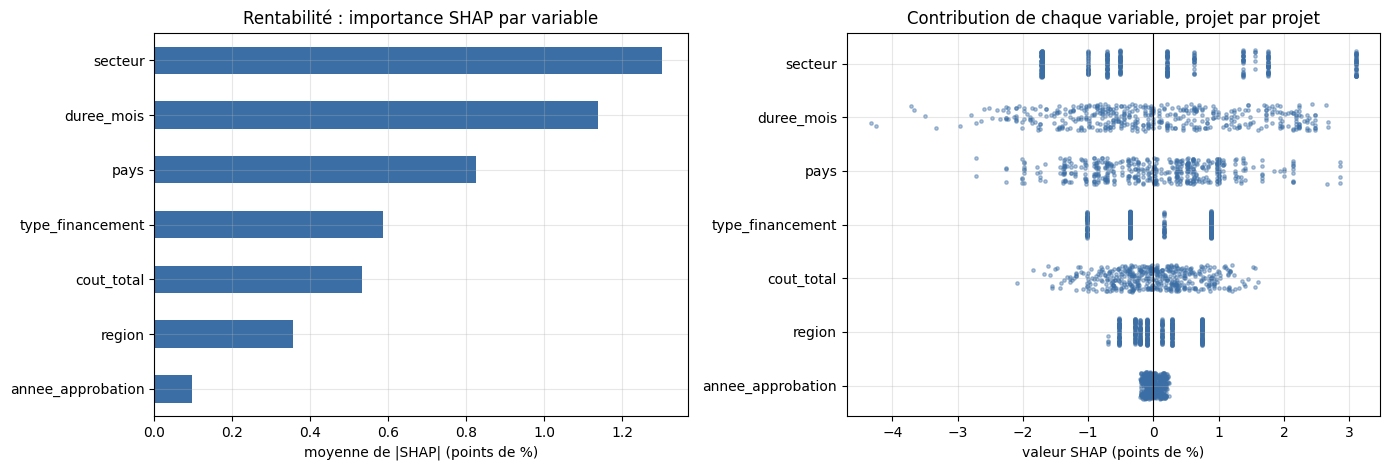

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
importance_rentabilite.sort_values().plot.barh(ax=axes[0], color="#3b6ea5")
axes[0].set(title="Rentabilité : importance SHAP par variable", xlabel="moyenne de |SHAP| (points de %)")

ordre = importance_rentabilite.index[::-1]
for i, variable in enumerate(ordre):
    valeurs = shap_rentabilite_variables[variable]
    axes[1].scatter(valeurs, np.full(len(valeurs), i) + np.random.default_rng(GRAINE).uniform(-0.25, 0.25, len(valeurs)),
                    s=6, alpha=0.4, color="#3b6ea5")
axes[1].set_yticks(range(len(ordre)), ordre)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(title="Contribution de chaque variable, projet par projet", xlabel="valeur SHAP (points de %)")
plt.tight_layout()
plt.savefig(FIGURES / "shap_rentabilite.png", dpi=120)
plt.show()

Lecture :

- **Le secteur est la variable la plus influente** (environ 1,3 point en moyenne), suivi de la **durée** (environ 1,1 point) et du **pays** (environ 0,8 point). Le financement et le coût viennent ensuite ; l'année ne compte presque pas.
- C'est exactement ce que dit la formule de simulation : effets de secteur de −2 à +2,5 points, effet de durée de −1,2 point par écart-type, effet pays tiré au hasard avec un écart-type de 1,5 point, effet de financement de ±1 point, l'année absente.
- La **région** a une importance SHAP d'environ 0,36 point alors qu'elle n'est pas dans la formule. Comme vu avec Lasso (tâche 6), le modèle s'en sert comme d'un résumé des pays voisins. La partie 3 montre que cette importance est trompeuse.
- Le nuage de droite montre la contribution de chaque variable pour chacun des 450 projets : la durée va d'environ −4 à +2,5 points (les projets très longs sont fortement pénalisés), le secteur de −2 à +3 points.

In [6]:
# Explication d'un projet : celui du test dont la rentabilité prédite est la plus haute.
predictions = modele_rentabilite.predict(evaluation[supervise.VARIABLES])
indice = int(np.argmax(predictions))
projet = evaluation.iloc[indice]
print(projet[["id_projet", "nom", "secteur", "pays", "cout_total", "duree_mois", "annee_approbation",
              "type_financement", "rentabilite"]].to_string())
contributions = shap_rentabilite_variables.iloc[indice].sort_values(key=abs, ascending=False)
print(f"\nMoyenne des prédictions : {explicateur.expected_value:.2f} %")
for variable, valeur in contributions.items():
    print(f"  {variable:<18} {valeur:+.2f}")
print(f"Prédiction : {explicateur.expected_value + contributions.sum():.2f} % (modèle : {predictions[indice]:.2f} %)")

id_projet                                      P087801
nom                  Power Sector Priority Investments
secteur                                        Énergie
pays                                       Timor-Leste
cout_total                                        1.41
duree_mois                                          44
annee_approbation                                 2004
type_financement                                 Autre
rentabilite                                       14.0

Moyenne des prédictions : 8.49 %
  secteur            +3.10
  pays               +1.94
  cout_total         +1.45
  duree_mois         +0.91
  region             +0.28
  type_financement   +0.16
  annee_approbation  +0.04
Prédiction : 16.37 % (modèle : 16.37 %)


Cet exemple montre l'additivité : la prédiction est la moyenne plus la somme des contributions. C'est le type d'explication que l'agent peut donner pour un projet (ici : « ce projet est jugé très rentable surtout parce qu'il est dans l'énergie, dans un pays à effet favorable, et très petit »).

### 2.2 Risque (LightGBM)

Pour un classifieur à trois classes, SHAP donne des contributions pour chaque classe. On regarde la classe **`eleve`**, celle de `proba_risque`. Les valeurs sont en **log-cote** (l'échelle interne du modèle, avant transformation en probabilité) : une contribution positive augmente la probabilité de risque élevé.

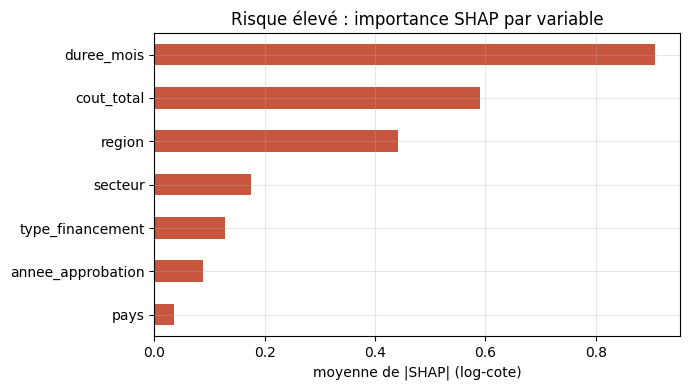

,importance SHAP (log-cote)
duree_mois,0.907
cout_total,0.591
region,0.442
secteur,0.176
type_financement,0.127
annee_approbation,0.088
pays,0.036


In [7]:
pretraitement_risque = modele_risque["pretraitement"]
colonnes_risque = pretraitement_risque.get_feature_names_out()
explicateur_risque = shap.TreeExplainer(modele_risque["modele"])
valeurs = np.asarray(explicateur_risque.shap_values(pretraitement_risque.transform(evaluation[supervise.VARIABLES])))
classe_eleve = list(modele_risque.classes_).index("eleve")
valeurs_eleve = valeurs[:, :, classe_eleve]  # forme : projets x colonnes x classes
shap_risque_variables = regrouper(valeurs_eleve, colonnes_risque)
importance_risque = shap_risque_variables.abs().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
importance_risque.sort_values().plot.barh(ax=ax, color="#c8553d")
ax.set(title="Risque élevé : importance SHAP par variable", xlabel="moyenne de |SHAP| (log-cote)")
plt.tight_layout()
plt.savefig(FIGURES / "shap_risque.png", dpi=120)
plt.show()
importance_risque.round(3).to_frame("importance SHAP (log-cote)")

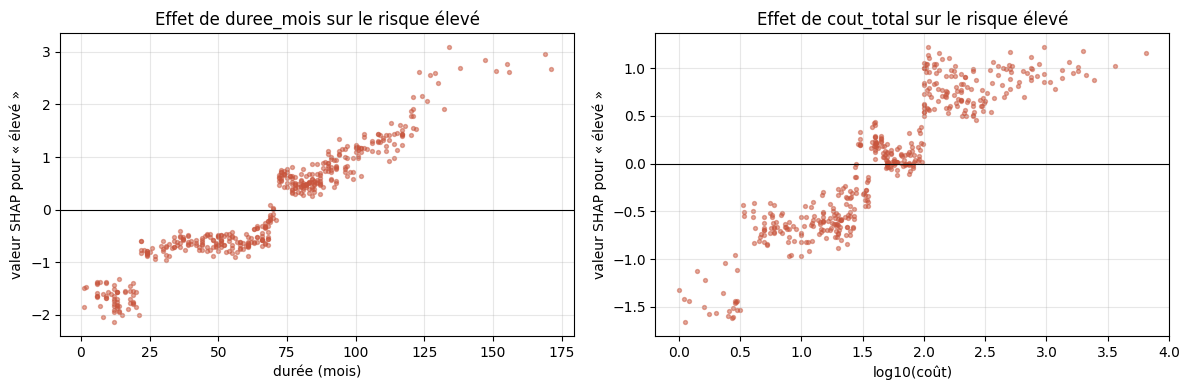

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, variable in zip(axes, ["duree_mois", "cout_total"]):
    x = evaluation[variable] if variable == "duree_mois" else np.log10(evaluation[variable])
    ax.scatter(x, shap_risque_variables[variable], s=8, alpha=0.5, color="#c8553d")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xlabel="durée (mois)" if variable == "duree_mois" else "log10(coût)",
           ylabel="valeur SHAP pour « élevé »", title=f"Effet de {variable} sur le risque élevé")
plt.tight_layout()
plt.savefig(FIGURES / "shap_risque_duree_cout.png", dpi=120)
plt.show()

Lecture :

- **La durée et le coût dominent**, puis la **région**. Le secteur, le financement et l'année jouent peu, le pays presque pas.
- C'est cohérent avec la formule du risque : score = −0,6 × rentabilité + 0,5 × durée + 0,4 × coût + effet de région + bruit. La durée intervient deux fois (directement, et à travers la rentabilité, qui baisse avec la durée) : c'est logique qu'elle passe en tête. Le secteur et le financement n'agissent qu'à travers la rentabilité, multipliée par −0,6, d'où leur poids plus faible.
- Les deux nuages montrent des effets **croissants et non linéaires** : plus le projet est long ou cher, plus la probabilité de risque élevé monte, avec une accélération pour les projets les plus longs. LightGBM capte ces courbes par ses découpages successifs.

## 3. Importance par permutation

**Le principe.** On mélange au hasard les valeurs d'**une** variable dans les données d'évaluation (ce qui casse son lien avec la cible, sans changer sa distribution), puis on mesure de combien le modèle se dégrade. On répète 20 fois et on fait la moyenne. Plus la dégradation est forte, plus le modèle a besoin de la variable.

Différence avec SHAP : SHAP dit **comment** le modèle utilise une variable ; la permutation dit **ce qu'on perd** sans elle. On permute les 7 variables d'origine (pas les 175 colonnes), directement à l'entrée du `Pipeline`.

Mesures : hausse de la RMSE (rentabilité, sur les projets d'évaluation dans les bornes) et baisse du F1 macro (risque, sur tous les projets d'évaluation).

In [9]:
evaluation_bornes = evaluation[supervise.dans_les_bornes(evaluation, bornes)]
permutation_rentabilite = permutation_importance(
    modele_rentabilite, evaluation_bornes[supervise.VARIABLES], evaluation_bornes[supervise.CIBLE_REGRESSION],
    scoring="neg_root_mean_squared_error", n_repeats=20, random_state=GRAINE)
permutation_risque = permutation_importance(
    modele_risque, evaluation[supervise.VARIABLES], evaluation[supervise.CIBLE_CLASSIFICATION],
    scoring="f1_macro", n_repeats=20, random_state=GRAINE)

permutations = pd.DataFrame({
    "rentabilité : hausse de la RMSE": permutation_rentabilite.importances_mean,
    "écart-type (rentabilité)": permutation_rentabilite.importances_std,
    "risque : baisse du F1 macro": permutation_risque.importances_mean,
    "écart-type (risque)": permutation_risque.importances_std,
}, index=supervise.VARIABLES)
permutations = permutations.assign(
    **{"rang SHAP rentabilité": importance_rentabilite.rank(ascending=False).astype(int),
       "rang permutation rentabilité": permutations["rentabilité : hausse de la RMSE"].rank(ascending=False).astype(int),
       "rang SHAP risque": importance_risque.rank(ascending=False).astype(int),
       "rang permutation risque": permutations["risque : baisse du F1 macro"].rank(ascending=False).astype(int)})
permutations.sort_values("rentabilité : hausse de la RMSE", ascending=False).round(3)

,rentabilité : hausse de la RMSE,écart-type (rentabilité),risque : baisse du F1 macro,écart-type (risque),rang SHAP rentabilité,rang permutation rentabilité,rang SHAP risque,rang permutation risque
secteur,0.802,0.052,0.029,0.012,1,1,4,4
duree_mois,0.699,0.050,0.219,0.021,2,2,1,1
pays,0.443,0.043,0.005,0.003,3,3,7,6
type_financement,0.217,0.022,0.004,0.009,4,4,5,7
cout_total,0.174,0.032,0.082,0.014,5,5,2,2
annee_approbation,0.015,0.005,0.024,0.008,7,6,6,5
region,0.014,0.017,0.070,0.016,6,7,3,3


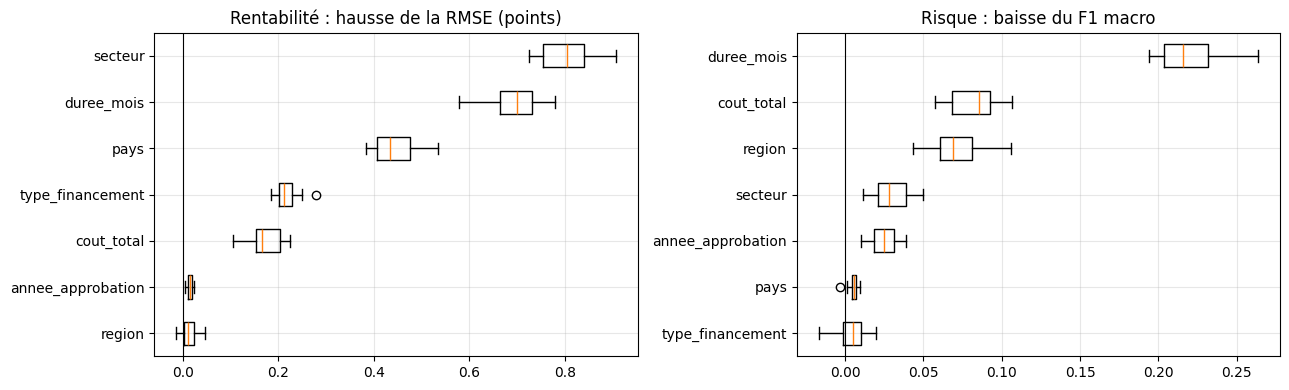

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, resultat, titre, couleur in [
    (axes[0], permutation_rentabilite, "Rentabilité : hausse de la RMSE (points)", "#3b6ea5"),
    (axes[1], permutation_risque, "Risque : baisse du F1 macro", "#c8553d"),
]:
    ordre = np.argsort(resultat.importances_mean)
    ax.boxplot(resultat.importances[ordre].T, vert=False, tick_labels=np.array(supervise.VARIABLES)[ordre])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=titre)
    ax.get_children()  # rien à faire : les boîtes montrent la dispersion sur les 20 mélanges
plt.tight_layout()
plt.savefig(FIGURES / "importance_permutation.png", dpi=120)
plt.show()

Lecture :

- **Rentabilité** : sans le secteur, la RMSE monte d'environ 0,8 point ; sans la durée, d'environ 0,7 ; sans le pays, d'environ 0,45. Le financement et le coût comptent un peu ; l'année et la région presque pas. Même ordre que SHAP pour les variables principales.
- **La région est le cas intéressant** : SHAP lui donne environ 0,36 point de contribution moyenne, mais la mélanger ne dégrade presque pas le modèle (moins de 0,02 point). Le modèle l'utilise, mais ne perd rien sans elle, car le pays contient déjà la même information. SHAP mesure l'usage, la permutation mesure la nécessité : il faut regarder les deux.
- **Risque** : la durée est de loin la plus nécessaire (environ 0,22 point de F1 macro perdu), puis le coût et la région. Le pays et le financement ne servent à rien pour le risque : c'est conforme à la formule, où le pays n'agit qu'à travers la rentabilité, de façon faible.
- Les deux méthodes s'accordent sur l'essentiel : les modèles s'appuient sur les variables qui comptent réellement dans la simulation, et pas sur des artefacts.

## 4. Les 10 plus grosses erreurs

On regarde les erreurs du modèle à 1 050 projets sur les 450 projets de validation et de test. Le fichier `anomalies_injectees.csv` sert ici **uniquement à lire les erreurs après coup**, jamais au modèle.

### 4.1 Rentabilité

In [11]:
anomalies = pd.read_csv(RACINE / "data" / "processed" / "anomalies_injectees.csv")
projets_par_pays = entrainement["pays"].value_counts()

erreurs = evaluation.assign(
    predite=modele_rentabilite.predict(evaluation[supervise.VARIABLES]),
    hors_bornes=~supervise.dans_les_bornes(evaluation, bornes),
    pays_a_l_entrainement=evaluation["pays"].map(projets_par_pays).fillna(0).astype(int),
)
erreurs["erreur"] = erreurs["predite"] - erreurs["rentabilite"]
erreurs = erreurs.merge(anomalies[["id_projet", "type_anomalie"]], on="id_projet", how="left")
erreurs["type_anomalie"] = erreurs["type_anomalie"].fillna("")

colonnes_affichees = ["id_projet", "secteur", "pays", "pays_a_l_entrainement", "cout_total", "duree_mois",
                      "annee_approbation", "type_financement", "rentabilite", "predite", "erreur",
                      "hors_bornes", "type_anomalie"]
dix_erreurs = erreurs.reindex(erreurs["erreur"].abs().sort_values(ascending=False).index).head(10)
dix_erreurs[colonnes_affichees].round(1)

,id_projet,secteur,pays,pays_a_l_entrainement,cout_total,duree_mois,annee_approbation,type_financement,rentabilite,predite,erreur,hors_bornes,type_anomalie
131,P121231,Numérique,Moldova,7,23.0,67,2011,IDA,-56.0,9.9,65.9,True,rentabilite_extreme
441,P177489,Transport,Rwanda,10,28.0,31,2023,Dons,-55.0,10.1,65.1,True,rentabilite_extreme
256,P008527,Finance,Latvia,3,25.0,48,1994,IBRD,50.5,11.1,-39.4,True,rentabilite_extreme
6,P002411,Énergie,Sierra Leone,8,69.9,122,1992,IDA,38.1,10.2,-27.9,True,rentabilite_extreme
211,P174927,Gouvernance,Dominica,1,25.0,9,2021,IDA,2.2,8.6,6.4,False,
408,P155339,Santé,Sierra Leone,8,3.0,47,2017,Dons,3.6,9.5,5.9,False,
201,P169279,Transport,Samoa,4,3.4,20,2019,IDA,7.0,12.7,5.7,False,
168,P156590,Industrie et commerce,Ethiopia,18,150.0,1,2017,IDA,7.5,13.0,5.5,False,duree_incoherente
418,P160182,Agriculture,"Congo, Democratic Republic of",9,6.2,60,2019,Autre,13.7,8.2,-5.5,False,
282,P052297,Éducation,Jordan,4,6.0,52,1998,IBRD,16.2,10.8,-5.4,False,


Trois familles d'erreurs :

1. **Les 4 rentabilités fabriquées** (lignes 1 à 4, erreurs de 28 à 66 points). La règle IQR les marque `hors_bornes` ; le modèle prédit pour elles une rentabilité normale (10 à 11 %), ce qui est la bonne réponse pour un projet de ce type. L'erreur vient de la cible, pas du modèle.
2. **Une durée fabriquée** (`duree_incoherente`, P156590) : la durée réelle a été remplacée par 1 mois. Le modèle croit à un projet très court, donc rentable (la durée pénalise la rentabilité), et surestime de 5,5 points. C'est l'erreur typique d'une **entrée** fausse : seul un détecteur d'anomalies (rôle 2) peut la repérer avant la prédiction.
3. **Des projets normaux** (les 5 autres), avec des erreurs de 5 à 6,5 points, soit environ 3 fois l'erreur typique. Points communs :
   - des **pays rares** à l'entraînement (Dominica : 1 projet, Samoa : 4, Jordanie : 4, Sierra Leone, RD Congo) : l'effet pays, tiré au hasard dans la simulation, est mal estimé avec si peu d'exemples, et Ridge le rapetisse vers 0 ;
   - souvent de **très petits projets** (3 à 25 millions de dollars) ;
   - et surtout le **bruit propre à chaque projet** de la simulation (écart-type 1,8 point) : un projet tiré à 3 écarts-types du centre ne peut pas être prédit.

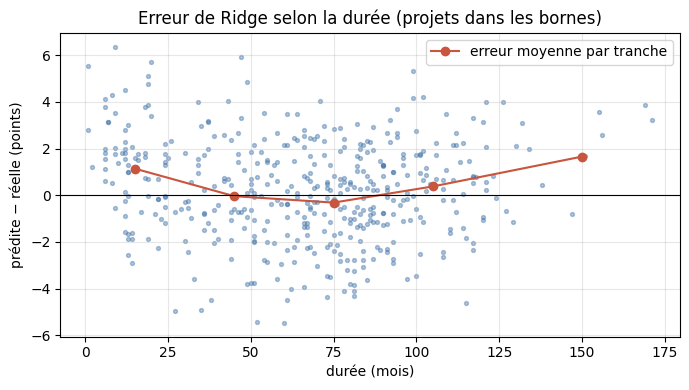

Erreur absolue moyenne : 1.73 points ; pays avec moins de 3 projets à l'entraînement : 1.85 (34 projets) ; autres : 1.72


,erreur moyenne (prédite − réelle),projets
duree_mois,,
"(0, 30]",1.14,81
"(30, 60]",-0.04,97
"(60, 90]",-0.32,163
"(90, 120]",0.38,86
"(120, 180]",1.66,19


In [12]:
dans = erreurs[~erreurs["hors_bornes"]]
tranches = pd.cut(dans["duree_mois"], [0, 30, 60, 90, 120, 180])
par_duree = dans.groupby(tranches, observed=True)["erreur"].agg(["mean", "count"])
par_duree.columns = ["erreur moyenne (prédite − réelle)", "projets"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(dans["duree_mois"], dans["erreur"], s=8, alpha=0.4, color="#3b6ea5")
milieux = [intervalle.mid for intervalle in par_duree.index]
ax.plot(milieux, par_duree.iloc[:, 0], color="#c8553d", marker="o", label="erreur moyenne par tranche")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Erreur de Ridge selon la durée (projets dans les bornes)", xlabel="durée (mois)",
       ylabel="prédite − réelle (points)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "erreurs_duree.png", dpi=120)
plt.show()

rare = dans["pays_a_l_entrainement"] < 3
print(f"Erreur absolue moyenne : {dans['erreur'].abs().mean():.2f} points ; "
      f"pays avec moins de 3 projets à l'entraînement : {dans.loc[rare, 'erreur'].abs().mean():.2f} "
      f"({rare.sum()} projets) ; autres : {dans.loc[~rare, 'erreur'].abs().mean():.2f}")
par_duree.round(2)

**Une erreur systématique aux deux extrémités de la durée.** Le modèle surestime la rentabilité des projets très longs (plus de 120 mois : environ +1,7 point en moyenne) **et** des projets très courts (moins de 30 mois : environ +1,1 point), alors qu'il est juste au milieu. C'est la **courbure** de la formule : le terme −0,5 × durée² (durée centrée-réduite) pénalise les projets qui s'écartent de la durée moyenne, dans un sens comme dans l'autre. Une droite ne peut pas suivre cette forme en cloche. Les arbres captent cette courbe, mais perdent davantage sur l'effet pays (tâche 6). Une amélioration possible, non testée ici pour ne pas rouvrir le test : ajouter la durée au carré comme variable dans le modèle linéaire.

Les pays rares ont une erreur un peu plus forte, mais l'écart est petit : le bruit propre à chaque projet domine.

### 4.2 Risque : les 10 erreurs les plus sûres d'elles

In [13]:
probas = modele_risque.predict_proba(evaluation[supervise.VARIABLES])
classes = list(modele_risque.classes_)
erreurs_risque = evaluation.assign(
    predit=modele_risque.predict(evaluation[supervise.VARIABLES]),
    confiance=probas.max(axis=1),
    proba_eleve=probas[:, classes.index("eleve")],
    rentabilite_predite=modele_rentabilite.predict(evaluation[supervise.VARIABLES]),
).merge(anomalies[["id_projet", "type_anomalie"]], on="id_projet", how="left")
erreurs_risque["type_anomalie"] = erreurs_risque["type_anomalie"].fillna("")
mauvaises = erreurs_risque[erreurs_risque["predit"] != erreurs_risque["risque"]]
print(f"{len(mauvaises)} projets mal classés sur {len(erreurs_risque)}, "
      f"dont {((mauvaises['predit'] == 'faible') & (mauvaises['risque'] == 'eleve')).sum()} élevés pris pour faibles "
      f"et {((mauvaises['predit'] == 'eleve') & (mauvaises['risque'] == 'faible')).sum()} faibles pris pour élevés")
dix_risque = mauvaises.sort_values("confiance", ascending=False).head(10).copy()
# Le vrai risque est-il plus haut que prévu alors que la rentabilité réelle est plus basse que prévu (ou l'inverse) ?
rang = {"faible": 0, "moyen": 1, "eleve": 2}
plus_risque = dix_risque["risque"].map(rang) > dix_risque["predit"].map(rang)
moins_rentable = dix_risque["rentabilite"] < dix_risque["rentabilite_predite"]
dix_risque["rentabilité explique l'écart"] = plus_risque == moins_rentable
normales = dix_risque["type_anomalie"] == ""
print(f"Vraie classe des 10 erreurs : {dix_risque['risque'].value_counts().to_dict()} ; "
      f"durées fabriquées : {(~normales).sum()} ; "
      f"autres projets où l'écart de rentabilité va dans le sens de l'erreur : "
      f"{dix_risque.loc[normales, "rentabilité explique l'écart"].sum()} sur {normales.sum()}")
dix_risque[["id_projet", "secteur", "region", "cout_total", "duree_mois", "rentabilite", "rentabilite_predite",
            "risque", "predit", "confiance", "rentabilité explique l'écart", "type_anomalie"]].round(2)

166 projets mal classés sur 450, dont 2 élevés pris pour faibles et 6 faibles pris pour élevés
Vraie classe des 10 erreurs : {'moyen': 10} ; durées fabriquées : 2 ; autres projets où l'écart de rentabilité va dans le sens de l'erreur : 6 sur 8


,id_projet,secteur,region,cout_total,duree_mois,rentabilite,rentabilite_predite,risque,predit,confiance,rentabilité explique l'écart,type_anomalie
413,P158235,Finance,Afrique de l'Est et australe,3.13,57,11.6,9.56,moyen,faible,0.92,False,
361,P113273,Agriculture,Afrique de l'Ouest et centrale,15.00,1,10.0,12.81,moyen,faible,0.91,True,duree_incoherente
275,P048588,Gouvernance,Asie de l'Est et Pacifique,89.30,117,6.8,4.77,moyen,eleve,0.91,True,
352,P107498,Gouvernance,Afrique de l'Ouest et centrale,30.00,11,7.8,9.61,moyen,faible,0.90,True,
168,P156590,Industrie et commerce,Afrique de l'Est et australe,150.00,1,7.5,13.03,moyen,faible,0.89,True,duree_incoherente
408,P155339,Santé,Afrique de l'Ouest et centrale,3.00,47,3.6,9.53,moyen,faible,0.89,True,
33,P041268,Transport,Asie de l'Est et Pacifique,952.00,90,10.4,9.62,moyen,eleve,0.89,True,
29,P036042,Finance,Asie de l'Est et Pacifique,49.00,97,6.4,6.50,moyen,eleve,0.88,False,
164,P154780,Eau et assainissement,Asie de l'Est et Pacifique,1069.44,80,9.3,8.10,moyen,eleve,0.88,True,
407,P154238,Agriculture,Europe et Asie centrale,12.00,127,7.0,6.34,moyen,eleve,0.88,True,


Lecture des 10 erreurs les plus « sûres d'elles » (le modèle donnait au moins 88 % à la mauvaise classe) :

- **Toutes concernent des projets vraiment `moyen`**, que le modèle place avec assurance à un extrême. La classe `moyen` est une tranche étroite entre deux seuils d'un score continu : un petit écart de score suffit pour en sortir.
- **2 sont des durées fabriquées** (1 mois au lieu de la vraie durée) : le modèle voit un projet très court, donc peu risqué, et répond `faible`. Encore une **entrée** fausse, que seul le détecteur du rôle 2 peut signaler.
- **Pour 6 des 8 autres, la rentabilité réelle explique l'erreur** : le score de risque contient −0,6 × la rentabilité. Un projet moins rentable que prévu est plus risqué que ses caractéristiques ne le laissent penser (et inversement). Or le modèle ne connaît pas la rentabilité réelle, inconnue pour les projets en cours : c'est une limite de fond, pas un défaut du modèle.
- Les 2 derniers relèvent du bruit propre au score de risque dans la simulation.

Sur les 450 projets, confondre `faible` et `eleve` n'arrive que 8 fois (2 élevés pris pour faibles, 6 faibles pris pour élevés) : les erreurs restent entre classes voisines.

## 5. Fichier pour l'application

L'onglet « Explication » de l'application affiche l'importance moyenne SHAP du modèle de rentabilité. On la calcule avec le **modèle livré** (réappris sur les 1 500 projets terminés, celui de `predict`), sur les **2 000 projets** de `projets.csv` (ceux que l'application montre), avec les colonnes regroupées par variable d'origine. Unité : points de rentabilité.

In [14]:
modeles_livres = supervise.charger_modeles()
livre = modeles_livres["rentabilite"]
projets = pd.read_csv(supervise.FICHIER_PROJETS)
termines = projets[projets["statut"] == "termine"]
bornes_livrees = modeles_livres["bornes"]
fond_livre = livre["pretraitement"].transform(
    termines.loc[supervise.dans_les_bornes(termines, bornes_livrees), supervise.VARIABLES])
explicateur_livre = shap.LinearExplainer(livre["modele"], shap.maskers.Independent(fond_livre, max_samples=len(fond_livre)))
valeurs_livrees = explicateur_livre(livre["pretraitement"].transform(projets[supervise.VARIABLES])).values
importance_livree = regrouper(valeurs_livrees, livre["pretraitement"].get_feature_names_out()).abs().mean()

shap_importance = (importance_livree.sort_values(ascending=False).rename_axis("variable")
                   .reset_index(name="importance"))
shap_importance["importance"] = shap_importance["importance"].round(4)
shap_importance.to_csv(RACINE / "reports" / "role1" / "shap_importance.csv", index=False)
comparaison = shap_importance.set_index("variable").assign(
    **{"modèle à 1 050 projets (validation + test)": importance_rentabilite.round(4)})
comparaison

Prédictions calculées d'avance pour 2000 projets.


,importance,modèle à 1 050 projets (validation + test)
variable,,
secteur,1.2954,1.3025
duree_mois,1.0090,1.1371
pays,0.8971,0.8243
type_financement,0.5852,0.5869
cout_total,0.5798,0.5318
region,0.2839,0.3566
annee_approbation,0.1502,0.0960


Le classement des variables est le même pour le modèle livré et pour le modèle évalué, avec des valeurs très proches : réapprendre sur les 1 500 projets n'a pas changé ce que le modèle a appris. Le fichier `reports/role1/shap_importance.csv` (colonnes `variable`, `importance`) est prêt pour l'application.

## 6. Bilan de l'interprétabilité

| Question | Réponse |
|---|---|
| Sur quoi s'appuie le modèle de rentabilité ? | Secteur, durée, pays, puis financement et coût ; l'année presque pas. C'est l'ordre de la formule de simulation. |
| Sur quoi s'appuie le modèle de risque ? | Durée, coût, région ; le pays et le financement ne servent à rien. Conforme à la formule. |
| SHAP et permutation sont-ils d'accord ? | Oui sur l'essentiel. Seule différence : la région, utilisée par Ridge (SHAP) mais inutile (permutation), car le pays contient la même information. |
| D'où viennent les grosses erreurs de rentabilité ? | Des cibles fabriquées (imprévisibles), d'une durée fabriquée (entrée fausse), du bruit propre à chaque projet et des pays rares. |
| Erreur systématique ? | Les projets très longs (plus de 120 mois, +1,7 point) et très courts (moins de 30 mois, +1,1 point) sont surestimés : courbure de la durée qu'un modèle linéaire ne suit pas. Piste : ajouter la durée au carré. |
| D'où viennent les erreurs de risque ? | Surtout de projets `moyen` proches d'un seuil ; puis de la rentabilité réelle, qui fait partie du score de risque mais n'est pas connue au moment de prédire, et des durées fabriquées. |